**Live Deployment Link:** https://YOUR-APP-NAME.streamlit.app/  *(replace with your real Streamlit link before submitting)*

# Heart Disease Prediction System

## Setup: Running This Notebook From Scratch

Follow these steps in a terminal, inside this project's folder, before opening the notebook.

### 1. Put the dataset in the folder
Download the dataset from https://archive.ics.uci.edu/dataset/45/heart+disease, extract the zip, and copy **`processed.cleveland.data`** into the same folder as this notebook.


### 2. Install the required packages
```
pip install -r requirements.txt
```


## Input and Output

### Inputs (Features / Attributes)

Only **4 input attributes** are used 

| **Input Feature/Attribute** | **Possible Values** |
| --------------------------- | ------------------- |
| **ChestPain** | Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic |
| **MaxHeartRate** | Low (below 130 bpm), Medium (130-159 bpm), High (160 bpm or more) |
| **STDepression** | Zero (0), Low (up to 1.5), High (above 1.5) |
| **ExerciseAngina** | No, Yes |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| -------------------- | ------------------- |
| **HeartDisease** | Yes, No |



## Code - Heart Disease Prediction

### Step 1: Import Libraries

In [34]:



import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [5]:
DATA_FILE = "processed.cleveland.data"


column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# Read the data file and load it into a pandas DataFrame
raw_data = pd.read_csv(DATA_FILE, names=column_names, na_values="?")

# Print a header to indicate that sample data is being displayed
print("\n\nSample Data (first 10 rows):")
print("============================\n")

# Configure pandas to display all columns 
pd.set_option("display.max_columns", None)

print(raw_data.head(10))



Sample Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

**Meaning of the attributes in the dataset**

| Attribute | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar above 120 mg/dl (1 = yes) |
| restecg | Resting ECG result (0, 1, 2) |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina (1 = yes, 0 = no) |
| oldpeak | ST depression induced by exercise relative to rest |
| slope | Slope of the peak exercise ST segment |
| ca | Number of major vessels (0-3) coloured by fluoroscopy |
| thal | Thalassemia test result (3 normal, 6 fixed defect, 7 reversible defect) |
| num | **Output**: diagnosis of heart disease (0 = none, 1-4 = disease present) |

In [6]:
# Print a header for clarity
print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(raw_data.columns)

# Print a header for instance count
print("\n\nNumber of Instances in Sample Data:", raw_data["age"].count())
print("========================================\n")

# Check for missing values
print("Missing values per column (only columns with gaps are shown):")
missing = raw_data.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "None")

# Check for duplicate rows
print("\nDuplicate rows:", raw_data.duplicated().sum())

# Distribution of the original output attribute
print("\nOriginal output ('num') distribution (0 = no disease, 1-4 = disease):")
print(raw_data["num"].value_counts().sort_index())



Attributes in Sample Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')


Number of Instances in Sample Data: 303

Missing values per column (only columns with gaps are shown):
ca      4
thal    2
dtype: int64

Duplicate rows: 0

Original output ('num') distribution (0 = no disease, 1-4 = disease):
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data

The sample data is **not** ready to use as it is, so the following pre-processing is performed:

o   The output `num` has values 0-4. All values 1-4 mean "disease present", so it is converted into a binary output: 0 = no heart disease, 1 = heart disease.

o   A few values are missing in `ca` and `thal`. They are filled with the most frequent value (mode).

In [9]:
processed_data = raw_data.copy()

# 1) Binary output: any value above 0 means heart disease is present
processed_data["target"] = (processed_data["num"] > 0).astype(int)
processed_data = processed_data.drop(columns="num")

# 2) Fill missing values with the mode of each column that has gaps
for column in processed_data.columns[processed_data.isnull().any()]:
    processed_data[column] = processed_data[column].fillna(processed_data[column].mode()[0])

print("Missing values after pre-processing:", int(processed_data.isnull().sum().sum()))
print("\nBinary output distribution (0 = No, 1 = Yes):")
print(processed_data["target"].value_counts().sort_index())

Missing values after pre-processing: 0

Binary output distribution (0 = No, 1 = Yes):
target
0    164
1    139
Name: count, dtype: int64


### Step 4: Feature Extraction

They are selected in two stages:

1. **Rank all attributes** based on input-out relationship(corelations).
2. **Choose 4** that are both strongly related and *easy for a user to type into a web form*.

`ca` (fluoroscopy) and `thal` (thallium stress test) rank high but need specialist hospital tests, so a normal user cannot enter them. They are excluded.



Correlation of each Attribute with the Output:

          correlation  strength (absolute)
thal            0.522                0.522
ca              0.460                0.460
exang           0.432                0.432
oldpeak         0.425                0.425
thalach        -0.417                0.417
cp              0.414                0.414
slope           0.339                0.339
sex             0.277                0.277
age             0.223                0.223
restecg         0.169                0.169
trestbps        0.151                0.151
chol            0.085                0.085
fbs             0.025                0.025


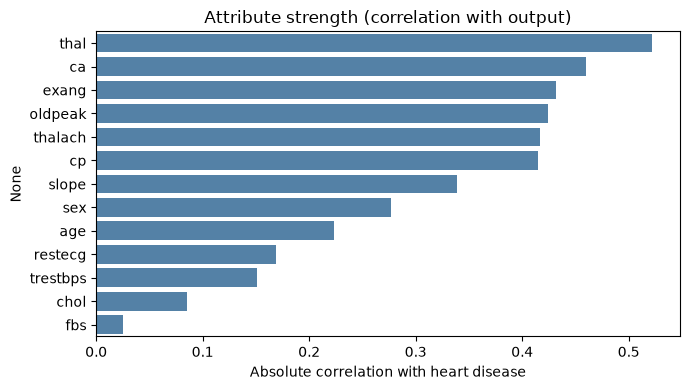

In [10]:
correlation_with_output = processed_data.corr()["target"].drop("target")

ranking = pd.DataFrame({
    "correlation": correlation_with_output,
    "strength (absolute)": correlation_with_output.abs()
}).sort_values("strength (absolute)", ascending=False)

print("\n\nCorrelation of each Attribute with the Output:")
print("===============================================\n")
print(ranking.round(3))

plt.figure(figsize=(7, 4))
sns.barplot(x=ranking["strength (absolute)"], y=ranking.index, color="steelblue")
plt.xlabel("Absolute correlation with heart disease")
plt.title("Attribute strength (correlation with output)")
plt.tight_layout()
plt.show()

**Selected 4 input attributes:** `cp` (chest pain type), `thalach` (maximum heart rate), `oldpeak` (ST depression) and `exang` (exercise-induced angina).

Note: `cp` is a category coded 1-4, so its correlation is only an approximation of its usefulness. The heatmap below also checks that the 4 chosen attributes are not strongly correlated with each other (no redundancy).

Just like the Titanic notebook, every input is then expressed as a **readable category** (for example Third / Male / Zero), so that Label Encoding in Step 5 works the same way. The two numeric attributes are grouped into bands:

- `thalach` (bpm): **Low** below 130, **Medium** 130-159, **High** 160 or more
- `oldpeak`: **Zero** equal to 0, **Low** up to 1.5, **High** above 1.5


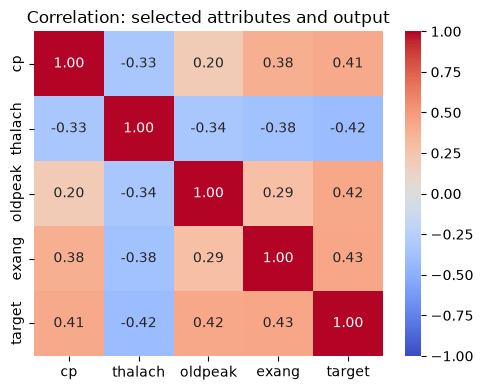

In [11]:

selected_attributes = ["cp", "thalach", "oldpeak", "exang"]

plt.figure(figsize=(5, 4))
sns.heatmap(processed_data[selected_attributes + ["target"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation: selected attributes and output")
plt.tight_layout()
plt.show()

In [12]:
def categorize_max_heart_rate(value):
    """Convert maximum heart rate (bpm) into Low / Medium / High."""
    if value < 130:
        return "Low"
    elif value < 160:
        return "Medium"
    return "High"

def categorize_st_depression(value):
    """Convert ST depression (oldpeak) into Zero / Low / High."""
    if value <= 0:
        return "Zero"
    elif value <= 1.5:
        return "Low"
    return "High"

chest_pain_names = {1: "Typical Angina", 2: "Atypical Angina", 3: "Non-anginal Pain", 4: "Asymptomatic"}
yes_no_names = {0: "No", 1: "Yes"}

sample_data = pd.DataFrame({
    "ChestPain":      processed_data["cp"].astype(int).map(chest_pain_names),
    "MaxHeartRate":   processed_data["thalach"].apply(categorize_max_heart_rate),
    "STDepression":   processed_data["oldpeak"].apply(categorize_st_depression),
    "ExerciseAngina": processed_data["exang"].astype(int).map(yes_no_names),
    "HeartDisease":   processed_data["target"].map(yes_no_names),
})

# Safety check: remove any row that still has a gap in the 4 selected attributes
rows_before = len(sample_data)
sample_data = sample_data.dropna().reset_index(drop=True)
print("Rows removed because of gaps:", rows_before - len(sample_data))

sample_data.to_csv("sample-data.csv", index=False, header=True)
print("Saved: sample-data.csv")

print("\n\nSample Data after Feature Extraction (first 10 rows):")
print("=====================================================\n")
print(sample_data.head(10))
print("\nShape:", sample_data.shape)

Rows removed because of gaps: 0
Saved: sample-data.csv


Sample Data after Feature Extraction (first 10 rows):

          ChestPain MaxHeartRate STDepression ExerciseAngina HeartDisease
0    Typical Angina       Medium         High             No           No
1      Asymptomatic          Low          Low            Yes          Yes
2      Asymptomatic          Low         High            Yes          Yes
3  Non-anginal Pain         High         High             No           No
4   Atypical Angina         High          Low             No           No
5   Atypical Angina         High          Low             No           No
6      Asymptomatic         High         High             No          Yes
7      Asymptomatic         High          Low            Yes           No
8      Asymptomatic       Medium          Low             No          Yes
9      Asymptomatic       Medium         High            Yes          Yes

Shape: (303, 5)


### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [13]:
# Define label categories for each feature
# These are possible values each column can have in the dataset
chest_pain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"]})
max_heart_rate = pd.DataFrame({"MaxHeartRate": ["Low", "Medium", "High"]})
st_depression = pd.DataFrame({"STDepression": ["Zero", "Low", "High"]})
exercise_angina = pd.DataFrame({"ExerciseAngina": ["No", "Yes"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# Create LabelEncoder objects for each categorical column
chest_pain_label_encoder = LabelEncoder()
max_heart_rate_label_encoder = LabelEncoder()
st_depression_label_encoder = LabelEncoder()
exercise_angina_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

# Train (fit) the encoders on the given categories
# np.ravel() flattens the DataFrame column into a 1D array for the encoder
chest_pain_label_encoder.fit(np.ravel(chest_pain))
max_heart_rate_label_encoder.fit(np.ravel(max_heart_rate))
st_depression_label_encoder.fit(np.ravel(st_depression))
exercise_angina_label_encoder.fit(np.ravel(exercise_angina))
heart_disease_label_encoder.fit(np.ravel(heart_disease))

# Show the numeric code given to every category
for name, encoder in [("ChestPain", chest_pain_label_encoder),
                      ("MaxHeartRate", max_heart_rate_label_encoder),
                      ("STDepression", st_depression_label_encoder),
                      ("ExerciseAngina", exercise_angina_label_encoder),
                      ("HeartDisease", heart_disease_label_encoder)]:
    print(name, "->", dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))

ChestPain -> {'Asymptomatic': np.int64(0), 'Atypical Angina': np.int64(1), 'Non-anginal Pain': np.int64(2), 'Typical Angina': np.int64(3)}
MaxHeartRate -> {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}
STDepression -> {'High': np.int64(0), 'Low': np.int64(1), 'Zero': np.int64(2)}
ExerciseAngina -> {'No': np.int64(0), 'Yes': np.int64(1)}
HeartDisease -> {'No': np.int64(0), 'Yes': np.int64(1)}


#### Step 5.2: Label Encode the Output

In [14]:
# Create copies of the dataset (one for encoded output, one to keep original)
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

# Transform "HeartDisease" (categorical -> numeric) using the trained LabelEncoder
print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
sample_data["encoded_heart_disease"] = heart_disease_label_encoder.transform(sample_data["HeartDisease"])

# Show original "HeartDisease" values and their numeric encodings
print(sample_data[["HeartDisease", "encoded_heart_disease"]].head(10))

# Replace the original output column with the encoded values
sample_data_encoded_output["HeartDisease"] = sample_data["encoded_heart_disease"]

# Save the encoded dataset to a CSV file (useful for training/testing later)
sample_data_encoded_output.to_csv(r"sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

  HeartDisease  encoded_heart_disease
0           No                      0
1          Yes                      1
2          Yes                      1
3           No                      0
4           No                      0
5           No                      0
6          Yes                      1
7           No                      0
8          Yes                      1
9          Yes                      1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [15]:
# Create copies of the dataset (to keep original values safe)
sample_data_encoded = sample_data_encoded_output.copy()

# Encode each input attribute
sample_data_encoded["ChestPain"] = chest_pain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded["MaxHeartRate"] = max_heart_rate_label_encoder.transform(sample_data_encoded_output["MaxHeartRate"])
sample_data_encoded["STDepression"] = st_depression_label_encoder.transform(sample_data_encoded_output["STDepression"])
sample_data_encoded["ExerciseAngina"] = exercise_angina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])

# Print encoded dataset (with numeric values instead of categories)
print("\n\nSample Data after Label Encoding (first 10 rows):")
print("=================================================\n")
print(sample_data_encoded.head(10))

# Save the encoded dataset to a new CSV file
sample_data_encoded.to_csv(r"sample-data-encoded.csv", index=False, header=True)
print("\nSaved: sample-data-encoded.csv")



Sample Data after Label Encoding (first 10 rows):

   ChestPain  MaxHeartRate  STDepression  ExerciseAngina  HeartDisease
0          3             2             0               0             0
1          0             1             1               1             1
2          0             1             0               1             1
3          2             0             0               0             0
4          1             0             1               0             0
5          1             0             1               0             0
6          0             0             0               0             1
7          0             0             1               1             0
8          0             2             1               0             1
9          0             2             0               1             1

Saved: sample-data-encoded.csv


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [16]:
# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# shuffle=True mixes the rows before splitting, and stratify keeps the same
# healthy / disease ratio in both parts (the UCI file is not in random order)
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data_encoded["HeartDisease"]
)

# Save the training and testing datasets to CSV files
training_data_encoded.to_csv(r"training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv(r"testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [17]:
# Extract input vectors (features) from training data
input_vector_train = training_data_encoded.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


### 6.3: Train the Support Vector Classifier

In [18]:
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters
svc_model = svm.SVC(gamma="auto", random_state=0)

# Train the model using the training data (features and labels)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [19]:

# Save the trained SVC model to a file named "svc_trained_model.pkl"
pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


**requirements.txt for deployment.** A pickled model must be loaded with the *same scikit-learn version* that trained it, otherwise the cloud app may fail or warn. The cell below writes a `requirements.txt` that pins the version installed on your computer.

In [20]:

import sklearn

with open("requirements.txt", "w") as file:
    file.write("streamlit\n")
    file.write("pandas\n")
    file.write("numpy\n")
    file.write(f"scikit-learn=={sklearn.__version__}\n")

print("Saved: requirements.txt")
print(open("requirements.txt").read())

Saved: requirements.txt
streamlit
pandas
numpy
scikit-learn==1.9.1



### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [21]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


### Step 7.2: Load the Saved Model

In [22]:


model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Models on Testing Data

In [23]:
model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv(r"model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by svc_trained_model (first 15 rows):")
print("==========================================================\n")
print(model_predictions.head(15))



Predictions Returned by svc_trained_model (first 15 rows):

     ChestPain  MaxHeartRate  STDepression  ExerciseAngina  HeartDisease  \
125          1             0             1               0             0   
83           2             2             0               1             1   
53           1             0             2               0             0   
45           2             0             0               0             1   
248          0             0             1               0             1   
211          3             0             0               1             1   
36           0             1             0               1             1   
106          0             0             2               1             1   
120          0             2             2               1             1   
31           0             0             1               1             1   
156          0             0             0               1             1   
157          0            

### Step 7.4: Calculate the Accuracy Score

In [24]:
model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.75


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.70      0.94      0.81        33
   Heart Disease (1)       0.88      0.54      0.67        28

            accuracy                           0.75        61
           macro avg       0.79      0.74      0.74        61
        weighted avg       0.79      0.75      0.74        61


Confusion Matrix:

                          Predicted: No Heart Disease  \
Actual: No Heart Disease                           31   
Actual: Heart Disease                              13   

                          Predicted: Heart Disease  
Actual: No Heart Disease                         2  
Actual: Heart Disease                           15  


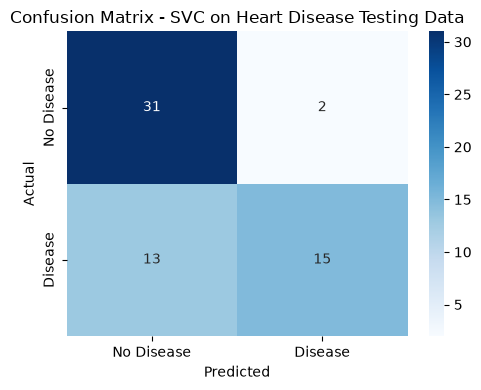

In [25]:
print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Heart Disease", "Actual: Heart Disease"],
    columns=["Predicted: No Heart Disease", "Predicted: Heart Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [26]:
# Demo patient (edit these values, or swap in input() calls as shown above)
chest_pain_input = "Asymptomatic"
max_heart_rate_input = 120
st_depression_input = 2.0
exercise_angina_input = "Yes"

print(f"ChestPain: {chest_pain_input}, MaxHeartRate: {max_heart_rate_input} bpm, "
      f"STDepression: {st_depression_input}, ExerciseAngina: {exercise_angina_input}")

ChestPain: Asymptomatic, MaxHeartRate: 120 bpm, STDepression: 2.0, ExerciseAngina: Yes


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [27]:

user_input = pd.DataFrame({
    "ChestPain": [chest_pain_input],
    "MaxHeartRate": [categorize_max_heart_rate(max_heart_rate_input)],
    "STDepression": [categorize_st_depression(st_depression_input)],
    "ExerciseAngina": [exercise_angina_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

      ChestPain MaxHeartRate STDepression ExerciseAngina
0  Asymptomatic          Low         High            Yes


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [35]:
unseen_data_features = user_input.copy()

unseen_data_features["ChestPain"] = chest_pain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["MaxHeartRate"] = max_heart_rate_label_encoder.transform(user_input["MaxHeartRate"])
unseen_data_features["STDepression"] = st_depression_label_encoder.transform(user_input["STDepression"])
unseen_data_features["ExerciseAngina"] = exercise_angina_label_encoder.transform(user_input["ExerciseAngina"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   ChestPain  MaxHeartRate  STDepression  ExerciseAngina
0          0             1             0               1


### Step 8.4: Load the Saved Model

In [ ]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))

### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [ ]:
predicted_heart_disease = model.predict(unseen_data_features)[0]

if predicted_heart_disease == 1:
    prediction = "HEART DISEASE LIKELY"
if predicted_heart_disease == 0:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [ ]:
"""
Step 9.1: Collect feedback by checking the model's predictions on a few
real-world-style patients whose expected result is known from basic clinical
knowledge (a domain expert would review the same cases). Each prediction below
is produced by the trained model, and the feedback column compares it with what
is expected.
"""

# (chest pain, max heart rate, ST depression, exercise angina, expected result)
review_cases = [
    ("Asymptomatic",     110, 2.5, "Yes", "Heart Disease"),
    ("Atypical Angina",  175, 0.0, "No",  "No Heart Disease"),
    ("Non-anginal Pain", 145, 1.0, "No",  "Borderline"),
]

feedback_rows = []
for cp_value, hr_value, st_value, ex_value, expected in review_cases:
    case = pd.DataFrame({
        "ChestPain": [chest_pain_label_encoder.transform([cp_value])[0]],
        "MaxHeartRate": [max_heart_rate_label_encoder.transform([categorize_max_heart_rate(hr_value)])[0]],
        "STDepression": [st_depression_label_encoder.transform([categorize_st_depression(st_value)])[0]],
        "ExerciseAngina": [exercise_angina_label_encoder.transform([ex_value])[0]],
    })
    predicted = "Heart Disease" if model.predict(case)[0] == 1 else "No Heart Disease"

    if expected == "Borderline":
        feedback = "Borderline case: either answer is defensible, a doctor must decide."
    elif predicted == expected:
        feedback = "Matches clinical expectation."
    else:
        feedback = "Unexpected: possible weakness of a 4-attribute model, needs investigation."

    feedback_rows.append({
        "Case": f"{cp_value}, {hr_value} bpm, ST {st_value}, angina {ex_value}",
        "Expected": expected,
        "Model Predicted": predicted,
        "Feedback": feedback,
    })

example_feedback = pd.DataFrame(feedback_rows)
print(example_feedback.to_string(index=False))

                                        Case         Expected  Model Predicted                                                            Feedback
   Asymptomatic, 110 bpm, ST 2.5, angina Yes    Heart Disease    Heart Disease                                       Matches clinical expectation.
 Atypical Angina, 175 bpm, ST 0.0, angina No No Heart Disease No Heart Disease                                       Matches clinical expectation.
Non-anginal Pain, 145 bpm, ST 1.0, angina No       Borderline No Heart Disease Borderline case: either answer is defensible, a doctor must decide.


#### Step 9.2: Make a List of Potential Improvements

In [ ]:

improvements = [
    "Use more attributes (e.g. age, sex, resting blood pressure, cholesterol) - the 4-attribute limit costs  accuracy  which is now 75% "
    "compared with using all 13 that gives accuracy of 85%+",
    "Use a larger and more varied dataset",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use more attributes (e.g. age, sex, resting blood pressure, cholesterol) - the 4-attribute limit costs  accuracy  which is now 75%compared with using all 13
2. Use a larger and more varied dataset


## Conclusion

In [ ]:
"""
Purpose of this section:
-------------------------
Prints a short conclusion using the real results from this run.
"""

print("Conclusion")
print("==========")
print(f"The Support Vector Classifier predicts heart disease from only 4 inputs "
      f"(chest pain type, maximum heart rate, ST depression, exercise-induced angina) "
      f"and reached an accuracy of {round(model_accuracy_score, 2)} on the held-out test set "
      f"({len(testing_data_encoded)} patients).")
print("See Step 7.5 for precision, recall and F1; recall of the 'Heart Disease' class is the most important for a screening tool.")
print("The model uses a small single-hospital dataset and is not a medical device.")

Conclusion
The Support Vector Classifier predicts heart disease from only 4 inputs (chest pain type, maximum heart rate, ST depression, exercise-induced angina) and reached an accuracy of 0.75 on the held-out test set (61 patients).
See Step 7.5 for precision, recall and F1; recall of the 'Heart Disease' class is the most important for a screening tool.
The model uses a small single-hospital dataset and is a learning demo, not a medical device.
